D:\Installations\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


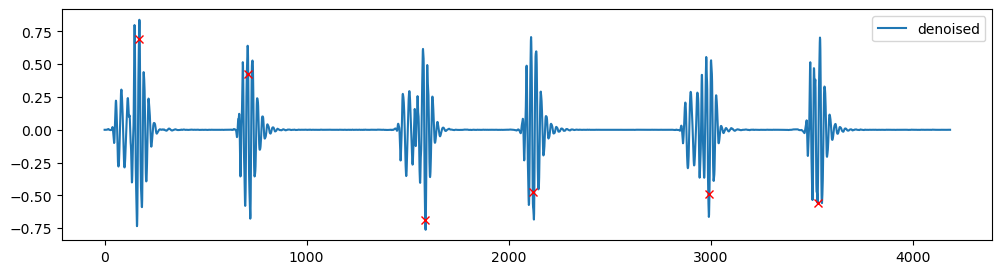

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sg
import librosa
import os
import sys
sys.path.append(os.path.abspath("../src"))

from wavelet_utils import wavelet_denoise



# --- Load with sr=2000 ---
file = "../data/train/normal/New_N_010.wav"
x, sr = librosa.load(file, sr=2000)

# --- Bandpass filter ---
def bandpass_filter(x, sr, low=25, high=400):
    b, a = sg.butter(4, [low, high], btype="bandpass", fs=sr)
    return sg.filtfilt(b, a, x)





# --- Segmentation ---
def segment_heart(x, sr):
    env = sg.savgol_filter(np.abs(sg.hilbert(x)), 101, 3)
    peaks, _ = sg.find_peaks(env, distance=int(0.2*sr), prominence=np.percentile(env, 70))
    segments = []
    for i in range(len(peaks)-1):
        start, end = peaks[i], peaks[i+1]
        seg = x[start:end]
        segments.append((start/sr, end/sr, seg))
    return segments, peaks

# --- Apply ---
x_filt = bandpass_filter(x, sr)
x_dn = wavelet_denoise(x_filt)
segments, peaks = segment_heart(x_dn, sr)

# --- Plot ---
plt.figure(figsize=(12,3))
plt.plot(x_dn, label="denoised")
plt.plot(peaks, x_dn[peaks], "rx")
plt.legend()
plt.show()



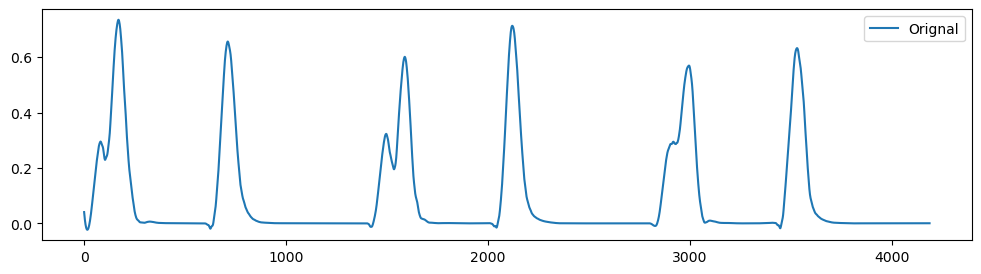

In [2]:
# --- Plot ---
env = sg.savgol_filter(np.abs(sg.hilbert(x_dn)), 101, 3)
plt.figure(figsize=(12,3))
plt.plot(env, label="Orignal")
plt.legend()
plt.show()